# Part 2: Supervised Learning Baseline (Naive Bayes vs Decision Tree)
**Course:** Introduction to Machine Learning
**Group:** 5
**Members:** Urooj Fatima Muddsar, Aayla Zahid, Fatima Naveed, Amina Saleem
**Dataset:** Adult Census Income (Kaggle)

## 1. Problem Statement
- **Task:** Binary classification
- **Target:** `income` (`<=50K` or `>50K`)
- **Goal of Part 2:** Train and compare a probabilistic model (Naive Bayes) and a tree-based model (Decision Tree) on the dataset prepared in Part 1.
- **Success metric:** F1-score (main), with ROC-AUC and accuracy as supporting metrics. Only about 24% of the people earn more than 50K, so accuracy alone is misleading.

In [3]:
import sys, subprocess
subprocess.check_call([sys.executable, "-m", "pip", "install",
                        "pandas", "numpy", "matplotlib", "seaborn", "scikit-learn"])

0

In [1]:
import warnings
warnings.filterwarnings("ignore")

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, OrdinalEncoder, KBinsDiscretizer
from sklearn.naive_bayes import GaussianNB, CategoricalNB
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, ConfusionMatrixDisplay, RocCurveDisplay,
                             classification_report)

RANDOM_STATE = 42
sns.set_theme(style="whitegrid")
pd.set_option("display.precision", 4)

## 2. Load Data
In this dataset missing values are written as `?`, so we convert them to NaN while loading.

In [2]:
filename = "../data/adult.csv"
df = pd.read_csv(filename, na_values="?", skipinitialspace=True)
df.columns = df.columns.str.replace(".", "_", regex=False)   # underscores are easier to use in code (education_num, ...)

print("Dataset loaded successfully!")
print("File:", filename)
print("Shape:", df.shape)

display(df.head())

Dataset loaded successfully!
File: ../data/adult.csv
Shape: (32561, 15)


,age,workclass,fnlwgt,education,education_num,marital_status,occupation,relationship,race,sex,capital_gain,capital_loss,hours_per_week,native_country,income
0,90,NaN,77053,HS-grad,9,Widowed,NaN,Not-in-family,White,Female,0,4356,40,United-States,<=50K
1,82,Private,132870,HS-grad,9,Widowed,Exec-managerial,Not-in-family,White,Female,0,4356,18,United-States,<=50K
2,66,NaN,186061,Some-college,10,Widowed,NaN,Unmarried,Black,Female,0,4356,40,United-States,<=50K
3,54,Private,140359,7th-8th,4,Divorced,Machine-op-inspct,Unmarried,White,Female,0,3900,40,United-States,<=50K
4,41,Private,264663,Some-college,10,Separated,Prof-specialty,Own-child,White,Female,0,3900,40,United-States,<=50K


In [3]:
# Target: 1 if income is >50K, else 0
y = df["income"].str.contains(">50K").astype(int)

# Same feature decisions as Part 1:
#  - drop `fnlwgt` (census sampling weight, not a personal attribute)
#  - drop `education` (redundant with the numeric `education_num`)
num_cols = ["age", "education_num", "capital_gain", "capital_loss", "hours_per_week"]
cat_cols = ["workclass", "marital_status", "occupation", "relationship", "race", "sex", "native_country"]
X = df[num_cols + cat_cols].copy()

print("Class balance (share of >50K):", round(y.mean(), 3))
print("\nMissing values per column:")
print(X.isna().sum()[X.isna().sum() > 0])

Class balance (share of >50K): 0.241

Missing values per column:
workclass         1836
occupation        1843
native_country     583
dtype: int64


## 3. Train/Test Split and Preprocessing
We split first (stratified 80/20), so the test set stays untouched until Section 7. All imputers, scalers, encoders and discretizers are inside `Pipeline` / `ColumnTransformer`, so during cross-validation they are fitted on each training fold only and no information leaks from the validation fold. As in Part 1, `fnlwgt` and `education` are not used.

Two preprocessors are needed because the models expect different inputs:
- **Dense preprocessor:** median imputation and scaling for numeric columns, an "Unknown" category and one-hot encoding for categorical columns. Used by Gaussian NB and the decision tree.
- **Categorical preprocessor:** numeric columns are binned into 5 quantile bins and categorical columns are ordinal-encoded. Used by `CategoricalNB`, which treats every feature as discrete.

In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE)
print("Train:", X_train.shape, "| Test:", X_test.shape)

# ---- Dense preprocessor (GaussianNB, Decision Tree) ----
def make_dense_prep():
    num = Pipeline([("imp", SimpleImputer(strategy="median")),
                    ("sc", StandardScaler())])
    cat = Pipeline([("imp", SimpleImputer(strategy="constant", fill_value="Unknown")),
                    ("ohe", OneHotEncoder(handle_unknown="ignore", sparse_output=False))])
    return ColumnTransformer([("num", num, num_cols), ("cat", cat, cat_cols)])

# ---- Categorical preprocessor (CategoricalNB) ----
# Only the *vocabulary* of each category is fixed up-front (no statistics are learned from data),
# so a rare category missing from a CV fold can never cause an index error.
vocab = [sorted(X[c].dropna().unique().tolist()) + ["Unknown"] for c in cat_cols]
N_BINS = 5
min_cats = np.array([N_BINS] * len(num_cols) + [len(v) for v in vocab])

def make_cat_prep():
    num = Pipeline([("imp", SimpleImputer(strategy="median")),
                    ("bin", KBinsDiscretizer(n_bins=N_BINS, encode="ordinal", strategy="quantile"))])
    cat = Pipeline([("imp", SimpleImputer(strategy="constant", fill_value="Unknown")),
                    ("ord", OrdinalEncoder(categories=vocab))])
    return ColumnTransformer([("num", num, num_cols), ("cat", cat, cat_cols)])

Train: (26048, 12) | Test: (6513, 12)


## 4. Hand-Worked Split: Information Gain and Gini
To show the mechanics, we take a **small worked case from the project data**: 14 training rows (5 earning >50K, 9 earning <=50K) and compare three candidate binary splits.

$$H(S) = -\sum_i p_i \log_2 p_i \qquad Gini(S) = 1-\sum_i p_i^2$$
$$IG(S,A) = H(S) - \sum_{v}\frac{|S_v|}{|S|}H(S_v) \qquad \Delta Gini = Gini(S) - \sum_v \frac{|S_v|}{|S|}Gini(S_v)$$

The code below prints every intermediate number so it can be checked by hand with a calculator.

In [5]:
train_df = X_train.copy()
train_df["target"] = y_train.values

# 5 positives + 9 negatives, shuffled -> a small, reproducible worked example
small = pd.concat([train_df[train_df.target == 1].sample(5, random_state=7),
                   train_df[train_df.target == 0].sample(9, random_state=7)])
small = small.sample(frac=1, random_state=7).reset_index(drop=True)

# Three simple candidate splits
small["Married"]      = np.where(small.marital_status == "Married-civ-spouse", "Yes", "No")
small["Bachelors+"]   = np.where(small.education_num >= 13, "Yes", "No")
small["Hours>40/wk"]  = np.where(small.hours_per_week > 40, "Yes", "No")
candidates = ["Married", "Bachelors+", "Hours>40/wk"]

small[["age", "marital_status", "education_num", "hours_per_week", "target"] + candidates]

,age,marital_status,education_num,hours_per_week,target,Married,Bachelors+,Hours>40/wk
0,59,Married-civ-spouse,9,40,0,Yes,No,No
1,23,Never-married,10,40,0,No,No,No
2,38,Married-civ-spouse,13,40,1,Yes,Yes,No
3,33,Divorced,10,40,0,No,No,No
4,47,Married-civ-spouse,9,30,1,Yes,No,No
5,43,Married-civ-spouse,9,40,1,Yes,No,No
6,26,Never-married,10,40,0,No,No,No
7,24,Never-married,9,40,0,No,No,No
8,45,Divorced,9,50,0,No,No,Yes
9,26,Never-married,9,40,0,No,No,No


In [6]:
def entropy(counts):
    n = sum(counts)
    return -sum((c / n) * np.log2(c / n) for c in counts if c > 0)

def gini(counts):
    n = sum(counts)
    return 1 - sum((c / n) ** 2 for c in counts)

def worked_split(data, feature, verbose=True):
    n = len(data)
    parent = [int((data.target == 0).sum()), int((data.target == 1).sum())]   # [<=50K, >50K]
    H_p, G_p = entropy(parent), gini(parent)
    if verbose:
        print(f"=== Split on '{feature}' ===")
        print(f"Parent S: n={n}, [<=50K, >50K]={parent}")
        print(f"  H(S)    = -({parent[0]}/{n})log2({parent[0]}/{n}) - ({parent[1]}/{n})log2({parent[1]}/{n}) = {H_p:.4f}")
        print(f"  Gini(S) = 1 - (({parent[0]}/{n})^2 + ({parent[1]}/{n})^2) = {G_p:.4f}")
    wH, wG = 0.0, 0.0
    for val, sub in data.groupby(feature):
        c = [int((sub.target == 0).sum()), int((sub.target == 1).sum())]
        h, g, w = entropy(c), gini(c), len(sub) / n
        wH += w * h
        wG += w * g
        if verbose:
            print(f"Branch {feature}={val}: n={len(sub)}, [<=50K, >50K]={c}, weight={len(sub)}/{n}={w:.4f}")
            print(f"  H = {h:.4f}   Gini = {g:.4f}")
    IG, dG = H_p - wH, G_p - wG
    if verbose:
        print(f"Weighted child entropy = {wH:.4f}  ->  Information Gain = {H_p:.4f} - {wH:.4f} = {IG:.4f}")
        print(f"Weighted child Gini    = {wG:.4f}  ->  Gini Gain        = {G_p:.4f} - {wG:.4f} = {dG:.4f}\n")
    return IG, dG

summary = pd.DataFrame(
    [worked_split(small, f, verbose=False) for f in candidates],
    index=candidates, columns=["Information Gain", "Gini Gain"])
print("Comparison of the three candidate splits:")
display(summary)

best = summary["Information Gain"].idxmax()
print(f"Best split by information gain: '{best}'\n")
_ = worked_split(small, best, verbose=True)

Comparison of the three candidate splits:


,Information Gain,Gini Gain
Married,0.6617,0.3401
Bachelors+,0.1134,0.0636
Hours>40/wk,0.0103,0.0068


Best split by information gain: 'Married'

=== Split on 'Married' ===
Parent S: n=14, [<=50K, >50K]=[9, 5]
  H(S)    = -(9/14)log2(9/14) - (5/14)log2(5/14) = 0.9403
  Gini(S) = 1 - ((9/14)^2 + (5/14)^2) = 0.4592
Branch Married=No: n=8, [<=50K, >50K]=[8, 0], weight=8/14=0.5714
  H = -0.0000   Gini = 0.0000
Branch Married=Yes: n=6, [<=50K, >50K]=[1, 5], weight=6/14=0.4286
  H = 0.6500   Gini = 0.2778
Weighted child entropy = 0.2786  ->  Information Gain = 0.9403 - 0.2786 = 0.6617
Weighted child Gini    = 0.1190  ->  Gini Gain        = 0.4592 - 0.1190 = 0.3401



In [7]:
# Sanity check: a depth-1 tree (stump) using the entropy criterion must pick the same split
# and report the same information gain as our manual calculation.
stump_X = pd.DataFrame({f: (small[f] == "Yes").astype(int) for f in candidates})
stump = DecisionTreeClassifier(max_depth=1, criterion="entropy", random_state=0).fit(stump_X, small.target)
t = stump.tree_
n = t.n_node_samples
ig_sklearn = t.impurity[0] - (n[1] / n[0]) * t.impurity[1] - (n[2] / n[0]) * t.impurity[2]
print("sklearn stump chose  :", candidates[t.feature[0]])
print("sklearn info. gain   :", round(ig_sklearn, 4))
print("manual info. gain    :", round(summary.loc[best, "Information Gain"], 4))

sklearn stump chose  : Married
sklearn info. gain   : 0.6617
manual info. gain    : 0.6617


**Reading the worked example.** The split with the highest information gain is the one that leaves the *purest* child nodes on average — i.e. it separates high earners from low earners best. A decision tree repeats exactly this calculation at every node (over all features and thresholds) and greedily takes the best split. (With only 14 rows this is an illustration, not evidence about the whole dataset — the full tree in Section 5 is trained on all of the training data.)

**Hand calculation for the best split (`Married`)** — the same numbers the code above prints, written out so they can be checked with a calculator.

* Parent S: 14 rows, 9 are ≤50K and 5 are >50K.
  * H(S) = −(9/14)·log₂(9/14) − (5/14)·log₂(5/14) = **0.9403**
  * Gini(S) = 1 − ((9/14)² + (5/14)²) = **0.4592**
* Branch `Married = No`: 8 rows, [8, 0] → pure node, so H = 0 and Gini = 0.
* Branch `Married = Yes`: 6 rows, [1, 5] → H = −(1/6)log₂(1/6) − (5/6)log₂(5/6) = 0.6500, Gini = 1 − ((1/6)² + (5/6)²) = 0.2778.
* Weighted child entropy = (8/14)·0 + (6/14)·0.6500 = 0.2786
  * **Information gain = 0.9403 − 0.2786 = 0.6617**
* Weighted child Gini = (8/14)·0 + (6/14)·0.2778 = 0.1190
  * **Gini gain = 0.4592 − 0.1190 = 0.3401**

`Married` has the highest gain of the three candidate splits, so a tree would choose it first.

## 5. Models and Cross-Validation
Models compared (all trained only on the training set, inside pipelines):
- **Dummy (majority class):** the floor, always predicts <=50K
- **Gaussian NB:** numeric features as Gaussians; one-hot columns are also treated as Gaussian features (a known approximation)
- **Categorical NB:** every feature is discretised or categorical, the natural Naive Bayes for mixed tabular data
- **Decision Tree (unpruned):** `criterion="gini"`, grows until pure
- **Decision Tree (tuned depth):** `max_depth` chosen by cross-validation in Section 5.1

**Cross-validation:** `StratifiedKFold(n_splits=5, shuffle=True)`. Stratification keeps the ~24% positive rate in every fold, which matters for an imbalanced target. The same folds are used for every model, so the comparison is paired and fair.

In [8]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
scoring = {"accuracy": "accuracy", "precision": "precision", "recall": "recall",
           "f1": "f1", "roc_auc": "roc_auc"}

def cv_scores(model):
    return cross_validate(model, X_train, y_train, cv=cv, scoring=scoring, n_jobs=-1)

### 5.1 Decision-tree depth analysis (choosing `max_depth` by cross-validation)

,max_depth,train_f1,cv_f1,train_acc,cv_acc
0,1,0.0000,0.0000,0.7592,0.7592
1,2,0.5557,0.5552,0.8280,0.8279
2,3,0.6132,0.6126,0.8440,0.8437
3,4,0.6200,0.6168,0.8454,0.8443
4,5,0.6349,0.6304,0.8519,0.8501
5,6,0.6466,0.6403,0.8578,0.8551
6,7,0.6582,0.6441,0.8608,0.8548
7,8,0.6836,0.6584,0.8647,0.8541
8,10,0.7161,0.6682,0.8735,0.8522
9,12,0.7376,0.6683,0.8834,0.8525


Best max_depth by CV F1: 12


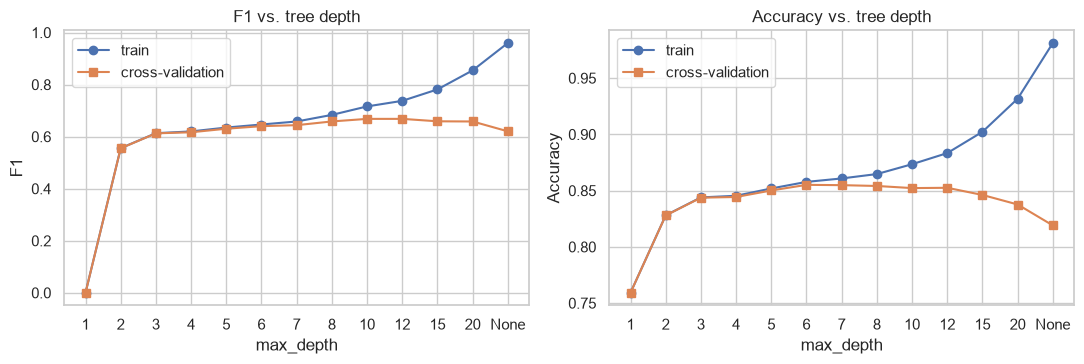

In [9]:
depths = [1, 2, 3, 4, 5, 6, 7, 8, 10, 12, 15, 20, None]
rows = []
for d in depths:
    model = Pipeline([("prep", make_dense_prep()),
                      ("clf", DecisionTreeClassifier(max_depth=d, random_state=RANDOM_STATE))])
    r = cross_validate(model, X_train, y_train, cv=cv, scoring=["f1", "accuracy"],
                       return_train_score=True, n_jobs=-1)
    rows.append({"max_depth": "None" if d is None else d,
                 "train_f1": r["train_f1"].mean(), "cv_f1": r["test_f1"].mean(),
                 "train_acc": r["train_accuracy"].mean(), "cv_acc": r["test_accuracy"].mean()})
depth_df = pd.DataFrame(rows)
best_depth_label = depth_df.loc[depth_df.cv_f1.idxmax(), "max_depth"]
best_depth = None if best_depth_label == "None" else int(best_depth_label)
display(depth_df)
print("Best max_depth by CV F1:", best_depth)

fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
for a, (tr, va, ttl) in zip(ax, [("train_f1", "cv_f1", "F1"), ("train_acc", "cv_acc", "Accuracy")]):
    a.plot(depth_df.max_depth.astype(str), depth_df[tr], "o-", label="train")
    a.plot(depth_df.max_depth.astype(str), depth_df[va], "s-", label="cross-validation")
    a.set_xlabel("max_depth"); a.set_ylabel(ttl); a.set_title(f"{ttl} vs. tree depth"); a.legend()
plt.tight_layout(); plt.show()

The gap between the training curve and the cross-validation curve at large depths is **overfitting**: the unpruned tree memorises the training data (train score → ~1.0) but generalises worse. A shallow tree trades a little training fit for better validation performance.

### 5.2 Cross-validation of all models

In [10]:
models = {
    "Dummy (majority)": Pipeline([("prep", make_dense_prep()),
                                  ("clf", DummyClassifier(strategy="most_frequent"))]),
    "Gaussian NB": Pipeline([("prep", make_dense_prep()),
                             ("clf", GaussianNB())]),
    "Categorical NB": Pipeline([("prep", make_cat_prep()),
                                ("clf", CategoricalNB(min_categories=min_cats, alpha=1.0))]),
    "Decision Tree (unpruned)": Pipeline([("prep", make_dense_prep()),
                                          ("clf", DecisionTreeClassifier(random_state=RANDOM_STATE))]),
    f"Decision Tree (depth={best_depth})": Pipeline([("prep", make_dense_prep()),
                                          ("clf", DecisionTreeClassifier(max_depth=best_depth,
                                                                         random_state=RANDOM_STATE))]),
}
tuned_name = f"Decision Tree (depth={best_depth})"

cv_results = {name: cv_scores(m) for name, m in models.items()}

cv_table = pd.DataFrame({
    name: {m: f"{r['test_' + m].mean():.3f} ± {r['test_' + m].std():.3f}" for m in scoring}
    for name, r in cv_results.items()}).T
cv_table.columns = ["Accuracy", "Precision", "Recall", "F1", "ROC-AUC"]
print("5-fold stratified CV on the training set (mean ± std across folds)")
display(cv_table)

5-fold stratified CV on the training set (mean ± std across folds)


,Accuracy,Precision,Recall,F1,ROC-AUC
Dummy (majority),0.759 ± 0.000,0.000 ± 0.000,0.000 ± 0.000,0.000 ± 0.000,0.500 ± 0.000
Gaussian NB,0.512 ± 0.008,0.327 ± 0.004,0.964 ± 0.006,0.488 ± 0.004,0.748 ± 0.019
Categorical NB,0.798 ± 0.004,0.559 ± 0.006,0.763 ± 0.009,0.646 ± 0.006,0.877 ± 0.002
Decision Tree (unpruned),0.819 ± 0.001,0.627 ± 0.004,0.614 ± 0.008,0.620 ± 0.003,0.767 ± 0.002
Decision Tree (depth=12),0.853 ± 0.005,0.732 ± 0.036,0.619 ± 0.049,0.668 ± 0.015,0.884 ± 0.005


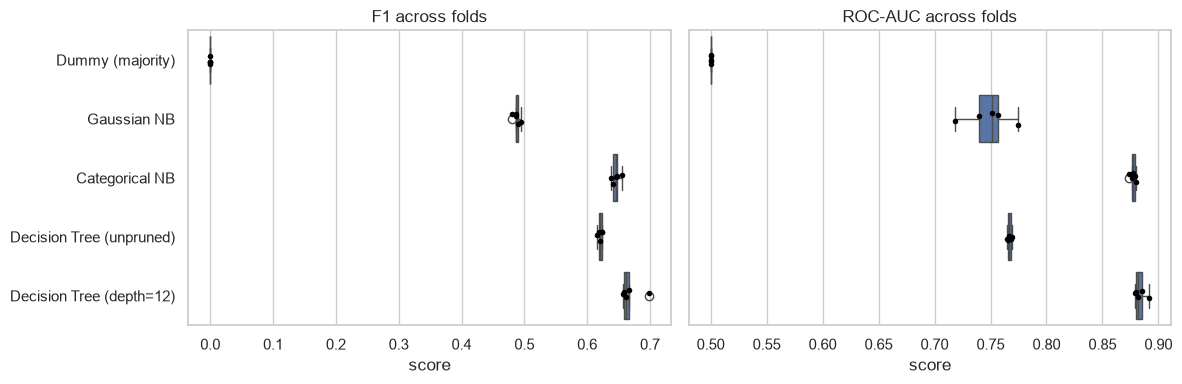

In [11]:
# Distribution of F1 / ROC-AUC across folds
long = pd.DataFrame([{"model": n, "metric": m, "score": s}
                     for n, r in cv_results.items() for m in ["f1", "roc_auc"] for s in r["test_" + m]])
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=False)
for ax, m, title in zip(axes, ["f1", "roc_auc"], ["F1 across folds", "ROC-AUC across folds"]):
    sns.boxplot(data=long[long.metric == m], y="model", x="score", ax=ax)
    sns.stripplot(data=long[long.metric == m], y="model", x="score", ax=ax, color="black", size=4)
    ax.set_title(title); ax.set_ylabel("")
axes[1].set_yticklabels([])
plt.tight_layout(); plt.show()

In [12]:
# Paired comparison on identical folds: best Naive Bayes vs. tuned tree (F1)
nb_names = ["Gaussian NB", "Categorical NB"]
best_nb = max(nb_names, key=lambda n: cv_results[n]["test_f1"].mean())
diff = cv_results[tuned_name]["test_f1"] - cv_results[best_nb]["test_f1"]
print(f"Per-fold F1 difference ({tuned_name} - {best_nb}):", np.round(diff, 4))
print(f"Mean difference: {diff.mean():+.4f} | tree wins in {(diff > 0).sum()} of {len(diff)} folds")

Per-fold F1 difference (Decision Tree (depth=12) - Categorical NB): [0.0117 0.0169 0.0179 0.0059 0.0609]
Mean difference: +0.0227 | tree wins in 5 of 5 folds


## 6. Inside the Decision Tree: Structure and Feature Importance

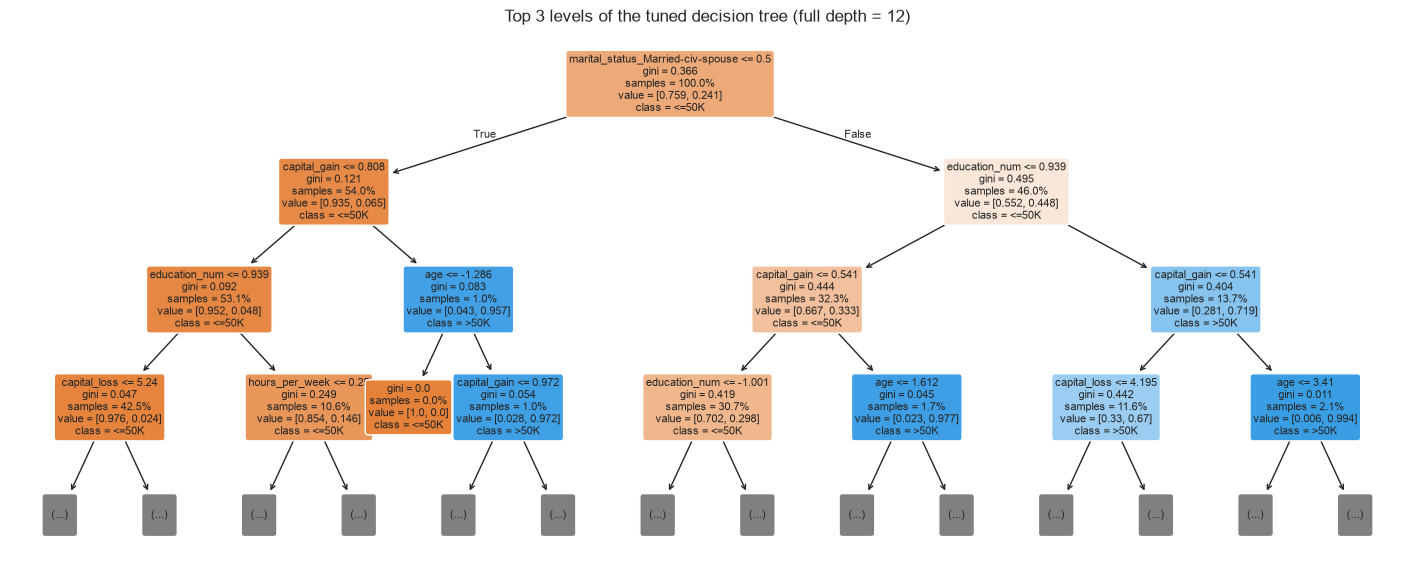

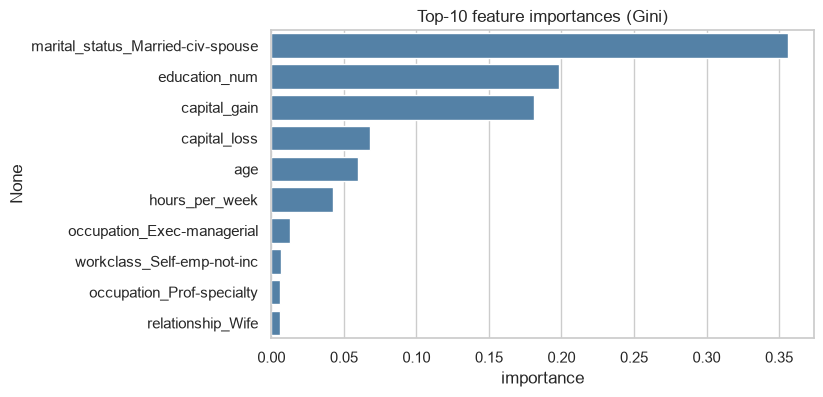

In [13]:
tree_pipe = models[tuned_name].fit(X_train, y_train)
prep = tree_pipe.named_steps["prep"]
tree = tree_pipe.named_steps["clf"]
feat_names = [n.split("__")[1] for n in prep.get_feature_names_out()]

plt.figure(figsize=(18, 7))
plot_tree(tree, feature_names=feat_names, class_names=["<=50K", ">50K"],
          max_depth=3, filled=True, rounded=True, fontsize=8, proportion=True)
plt.title(f"Top 3 levels of the tuned decision tree (full depth = {tree.get_depth()})")
plt.show()

imp = pd.Series(tree.feature_importances_, index=feat_names).sort_values(ascending=False).head(10)
plt.figure(figsize=(7, 4))
sns.barplot(x=imp.values, y=imp.index, color="steelblue")
plt.title("Top-10 feature importances (Gini)"); plt.xlabel("importance"); plt.show()

## 7. Held-Out Test Evaluation

The test set has not been used for any decision so far (not for preprocessing, not for choosing `max_depth`). Each model is refitted on the full training set and evaluated **once**.

In [14]:
fitted = {name: m.fit(X_train, y_train) for name, m in models.items()}
test_rows = {}
for name, m in fitted.items():
    pred = m.predict(X_test)
    proba = m.predict_proba(X_test)[:, 1]
    test_rows[name] = {"Accuracy": accuracy_score(y_test, pred),
                       "Precision": precision_score(y_test, pred, zero_division=0),
                       "Recall": recall_score(y_test, pred),
                       "F1": f1_score(y_test, pred),
                       "ROC-AUC": roc_auc_score(y_test, proba)}
test_table = pd.DataFrame(test_rows).T
display(test_table)

,Accuracy,Precision,Recall,F1,ROC-AUC
Dummy (majority),0.7593,0.0000,0.0000,0.0000,0.5000
Gaussian NB,0.5202,0.3286,0.9522,0.4886,0.7647
Categorical NB,0.7975,0.5588,0.7551,0.6423,0.8770
Decision Tree (unpruned),0.8159,0.6263,0.5835,0.6042,0.7527
Decision Tree (depth=12),0.8523,0.7484,0.5823,0.6549,0.8740


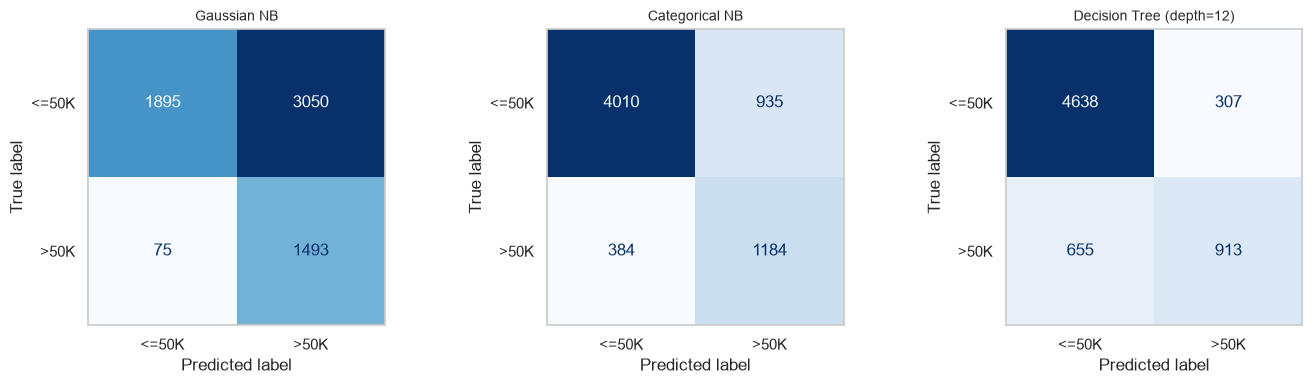

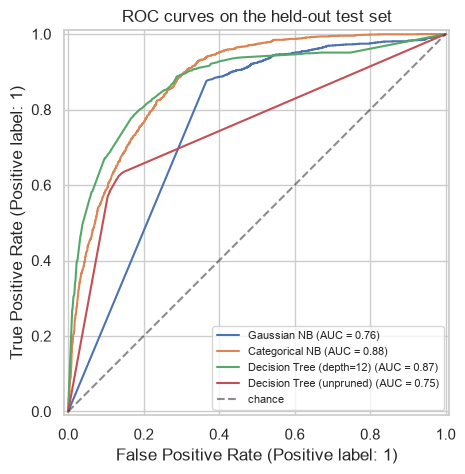

              precision    recall  f1-score   support

       <=50K       0.88      0.94      0.91      4945
        >50K       0.75      0.58      0.65      1568

    accuracy                           0.85      6513
   macro avg       0.81      0.76      0.78      6513
weighted avg       0.85      0.85      0.85      6513



In [15]:
show = ["Gaussian NB", "Categorical NB", tuned_name]

fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, name in zip(axes, show):
    ConfusionMatrixDisplay.from_estimator(fitted[name], X_test, y_test, display_labels=["<=50K", ">50K"],
                                          cmap="Blues", colorbar=False, ax=ax)
    ax.set_title(name, fontsize=10); ax.grid(False)
plt.tight_layout(); plt.show()

fig, ax = plt.subplots(figsize=(6, 5))
for name in show + ["Decision Tree (unpruned)"]:
    RocCurveDisplay.from_estimator(fitted[name], X_test, y_test, name=name, ax=ax)
ax.plot([0, 1], [0, 1], "k--", alpha=0.5, label="chance")
ax.set_title("ROC curves on the held-out test set"); ax.legend(fontsize=8, loc="lower right")
plt.show()

print(classification_report(y_test, fitted[tuned_name].predict(X_test), target_names=["<=50K", ">50K"]))

## 8. Comparison and Discussion

In [16]:
# Auto-generated summary of the numbers above (so the text always matches the results)
nb_best_test = max(nb_names, key=lambda n: test_table.loc[n, "F1"])
tt, nt = test_table.loc[tuned_name], test_table.loc[nb_best_test]
print(f"Best Naive Bayes on test : {nb_best_test}  (F1={nt['F1']:.3f}, AUC={nt['ROC-AUC']:.3f}, "
      f"Recall={nt['Recall']:.3f}, Precision={nt['Precision']:.3f})")
print(f"Tuned Decision Tree      : {tuned_name}  (F1={tt['F1']:.3f}, AUC={tt['ROC-AUC']:.3f}, "
      f"Recall={tt['Recall']:.3f}, Precision={tt['Precision']:.3f})")
winner = tuned_name if tt["F1"] > nt["F1"] else nb_best_test
print(f"\nWinner by held-out F1: {winner}")
print(f"Unpruned tree F1 (test) : {test_table.loc['Decision Tree (unpruned)', 'F1']:.3f}  "
      f"vs. tuned tree {tt['F1']:.3f}")
print(f"Majority-class accuracy : {test_table.loc['Dummy (majority)', 'Accuracy']:.3f}  "
      f"(any useful model must clearly beat this)")

Best Naive Bayes on test : Categorical NB  (F1=0.642, AUC=0.877, Recall=0.755, Precision=0.559)
Tuned Decision Tree      : Decision Tree (depth=12)  (F1=0.655, AUC=0.874, Recall=0.582, Precision=0.748)

Winner by held-out F1: Decision Tree (depth=12)
Unpruned tree F1 (test) : 0.604  vs. tuned tree 0.655
Majority-class accuracy : 0.759  (any useful model must clearly beat this)


### Write-up (½ page)

**Which model performed better?** The tuned decision tree (`max_depth = 12`) performed slightly better than the best Naive Bayes variant (Categorical NB). In 5-fold cross-validation its F1 was 0.668 against 0.646 and its ROC-AUC was 0.884 against 0.877; it won in all 5 folds (mean F1 difference +0.023). On the held-out test set the tree reached F1 = 0.655 and ROC-AUC = 0.874, against F1 = 0.642 and ROC-AUC = 0.877 for Categorical NB, so the gap is small and the two models are practically tied in ROC-AUC. They differ in the precision/recall trade-off: the tree is more precise (0.748 vs 0.559), while Categorical NB finds more high earners (recall 0.755 vs 0.582). Both beat the majority-class baseline, which reaches 0.759 accuracy but F1 = 0 because it never predicts >50K, which is why we do not rely on accuracy alone. Gaussian NB was the weakest model: its accuracy (0.520) was even below the baseline, with recall 0.952 but precision only 0.329.

**Why the models differ:**
* Naive Bayes assumes the features are independent given the class. In census data they are strongly related (marital status, relationship and sex; education and occupation), so the same evidence is effectively counted several times.
* Gaussian NB treats one-hot columns and skewed variables such as capital gain (zero for most people) as bell curves, which fits badly. Categorical NB treats every feature as discrete and performs much better (test F1 0.642 vs 0.489).
* A decision tree learns interactions and thresholds directly (for example married and high education, or capital gain above a cut-off) without an independence assumption, and it needs no feature scaling.

**Trade-offs and caveats:**
* The unpruned tree overfits: its training F1 is 0.96 but its CV F1 is only 0.62. Limiting the depth to 12 raises the test F1 from 0.604 to 0.655.
* Naive Bayes is very fast and has high recall, so it is useful when missing a high earner is costly. The tree gives higher precision, which is better when false alarms are costly.
* A single tree is unstable to small changes in the data. This motivates the ensembles (Random Forest, boosting) and regularisation in Part 3, which should improve on this baseline.
* All preprocessing ran inside pipelines, so the cross-validation and test scores are leakage-free.


## 9. Summary
In Part 2 we trained and compared Naive Bayes (Gaussian and Categorical) and a decision tree on the Adult Census Income dataset, using the same stratified split and leakage-free pipelines as in Part 1. With stratified 5-fold cross-validation and a held-out test set, the depth-tuned decision tree (`max_depth = 12`) was slightly better than the best Naive Bayes model (Categorical NB): test F1 0.655 vs 0.642 and test ROC-AUC 0.874 vs 0.877. The tree is more precise, while Naive Bayes finds more high earners (higher recall). Gaussian NB was the weakest model, and the unpruned tree overfitted. A hand-worked information-gain / Gini calculation (information gain 0.6617 for the `Married` split) matched scikit-learn. In Part 3 we will improve on this baseline with ensembles, regularization and hyperparameter tuning.